<a href="https://colab.research.google.com/github/jonathant11001/MTA-subway-disruptions-analysis/blob/main/notebooks/Clean_and_Categorized_MTA_Subway_Alerts_2023_2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Loading Data**


In [ ]:
import re
import pandas as pd

df = pd.read_csv("MTA_Service_Alerts__Beginning_April_2020_20261020.csv", dtype=str)

#Fixed Date Format and added Update Number(count of updates)
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y %I:%M:%S %p")
df["Update Number"] = df["Update Number"].astype(int)

display(df.columns)
display(df.head(2))

Index(['Alert ID', 'Event ID', 'Update Number', 'Date', 'Agency',
       'Status Label', 'Affected', 'Header', 'Description'],
      dtype='object')

,Alert ID,Event ID,Update Number,Date,Agency,Status Label,Affected,Header,Description
0,538085,262727,0,2026-08-12 01:08:00,BT,planned-work,Hugh L. Carey Tunnel,HLC: PLANNED WORK; One tube is closed; the rem...,NaN
1,538083,262726,0,2026-08-11 23:52:00,MNR,some-delays,Danbury,The 6:45pm train from Danbury to Stamford is o...,NaN


## **Code to check specific incident (Used when checking sample data)**

In [ ]:
event = "220654"

display(df[df["Event ID"] == event][["Event ID", "Agency", "Date", "Header","Description"]])

,Event ID,Agency,Date,Header,Description
84470,220654,NYCT Subway,2025-10-03 23:34:00,Tottenville-bound SIR trains are running with ...,NaN
84471,220654,NYCT Subway,2025-10-03 23:35:00,Tottenville-bound SIR trains are running with ...,NaN


## **Filter to subway, 2023–2025**

In [ ]:
df = df[df["Agency"] == "NYCT Subway"]
df = df[(df["Date"] >= "2023-01-01") & (df["Date"] < "2026-01-01")]

print(len(df), "subway updates in 2023-2025")

137698 subway updates in 2023-2025


## **Clean the alert text, format affected trains, and remove system tests**

In [ ]:
# Event ID and Alert ID as numbers so they match the AI file later
df["Event ID"] = df["Event ID"].astype(int)
df["Alert ID"] = df["Alert ID"].astype(int)

# Combining header and description into alert_text
df["Header"] = df["Header"].fillna("").str.replace(r"\s+", " ", regex=True).str.strip()
df["alert_text"] = df["Header"] + " " + df["Description"].fillna("")

# Cleaning alert_text before categorizing
df["alert_text"] = df["alert_text"].str.replace(r"(?is)planned work reminder.*", "", regex=True)

df["alert_text"] = (df["alert_text"]
                    .str.replace(r"\s+", " ", regex=True)
                    .str.replace("’", "'")
                    .str.strip())

# Changing multiple affected trains to be seperated by commas
df["Affected"] = (df["Affected"].fillna("").str.split("|")
                  .apply(lambda routes: ", ".join(r.strip() for r in routes if r.strip())))

# Remove MTA system tests and internal messages (the whole event, judged by its first update)
test_pattern = (r"this is a test of|testing stuff|asdf|test bullets|"
                r"do not publish|lite copy|screens? only|^\s*$|^nan$")
df = df.sort_values(["Event ID", "Update Number", "Date"])
first_updates = df.drop_duplicates("Event ID", keep="first")
test_events = first_updates.loc[first_updates["alert_text"].str.contains(test_pattern, case=False, regex=True), "Event ID"]
df = df[~df["Event ID"].isin(test_events)].copy()

print(f"Removed {len(test_events)} test/internal events")
print(f"{len(df):,} updates kept")

Removed 20 test/internal events
137,676 updates kept


## **Merge alerts into one row per event**

In [ ]:
# Combines all alerts with the same event id together
def combine_routes(values):
    routes = []
    for value in values:
        for route in value.split(", "):
            if route and route not in routes:
                routes.append(route)
    return ", ".join(routes)

incidents = (df.groupby("Event ID")
               .agg(start_ts=("Date", "min"),
                    end_ts=("Date", "max"),
                    n_updates=("Alert ID", "count"),
                    route=("Affected", combine_routes))
               .reset_index()
               .rename(columns={"Event ID": "event_id"}))

incidents["duration_min"] = ((incidents["end_ts"] - incidents["start_ts"])
                             .dt.total_seconds() / 60).round().astype(int)

print(f"{len(incidents):,} unique events")
incidents.head()

60,648 unique events


,event_id,start_ts,end_ts,n_updates,route,duration_min
0,89187,2023-01-01 00:04:00,2023-01-01 00:04:00,1,"4, 5",0
1,89192,2023-01-01 00:27:00,2023-01-01 00:39:00,2,F,12
2,89195,2023-01-01 00:56:00,2023-01-01 01:52:00,2,F,56
3,89199,2023-01-01 01:31:00,2023-01-01 02:48:00,4,"6, 5",77
4,89204,2023-01-01 02:05:00,2023-01-01 03:10:00,3,A,65


## **Define the categories**

Order matters: when an alert matches several rules, the first rule wins. The same order is the priority list in the AI prompt. Police / disruptive person appears twice: specific behavior near the top, and a bare "NYPD investigation" near the bottom, so a specific cause in another update wins.

In [ ]:
RULES = [
    ("Person on tracks / struck by train",
     r"struck by (a|at|an)? ?(\w+ )?train|someone who was struck|person (was )?struck|(person|someone|people) (on|in) the track|unauthorized (person|people|individual)|someone unauthorized|trespass"),
    ("Police / disruptive person",
     r"disruptive|assault|\bfight|unruly|disorderly|riding (on )?(the )?(outside|back|between)|hold(ing|s)? (open )?(the |a )?(train'?s? )?doors|held (open )?(the |a )?(train'?s? )?doors"),
    ("Medical emergency",
     r"someone in need|person in need|in need of [\w\s]{0,20}?(help|assistance)|\bsick\b|injured|medical|\bems\b|lost child|(requested|request|get) help for someone|assisted (a|someone|a person|a customer)"),
    ("Fire / smoke",
     r"\bfire\b|smoke|smoldering"),
    ("Weather / fallen trees",
     r"weather|\bsnow|\bice\b|\bicy\b|rainfall|\brain\b|\bstorm|high winds|extreme heat|heat.related|"
     r"^(?!.*(water main|pipe|sprinkler)).*flood|"
     r"\btrees?\b|tree branch(es)?|slippery|fallen leaves"),
    ("Track / power / infrastructure",
     r"(urgent|emergency) [\w\s-]{0,15}?(track|rail|switch|repair)|(broken|damaged) rail|repair(ing|ed)? (a |the )?rails?|replac(e|ed|ing) (a )?rails?|dropp?(ing|ed)? (a )?rails?|rail replacement|switch (problem|malfunction|issue|trouble)|unable to move (track )?switches|repair(ing)? (the |a )?switch|third.?rail.?power|thrid rail|loss (of )?power|restor(e|ed|ing) (third.rail )?power|water main|water|debris|lighting|structural|gap fillers?|platform extenders?|platform obstruction|remove (a|an) (shopping cart|shopping|wheelchair|walker|crane|scooter|bicycle|bike|object|item)|canine|animal"),
    ("Planned work",
     r"planned [\w\s-]{0,30}?(work|improvement|update|installation|upgrade|replacement)|improvements?\b|upgrades?\b|software update|\bwork (in|along|near|at|from|taking place)\b|signal (maintenance|modernization)|modernizing signals|switch maintenance|maint\w*n\w*ce\b|track work|move (work )?equipment|moved equipment|work train|work equipment|garbage (collection )?train|refuse (collection )?train|track inspection|inspect(ing|ed)? (the )?tracks?"),
    ("Signal problems",
     r"signal|network communications? (problem|issue)"),
    ("Brake activation",
     r"br[ae]a?kes?.{0,25}acti?v|activated (a|the|at) train'?s brakes|brake cord"),
    ("Train / car problem",
     r"mechanical|doors? (problem|malfunction|issue|trouble)|door trouble|vandaliz|broken window|clean(ing|ed)?\b|to be cleaned|in need (of|for) repairs?|needs? repairs?|to be repaired|unable to move a train|disabled train|stalled train|derail"),
    ("Crew / train availability",
     r"(crews|operators|conductors) (that )?(are |we have )?available|crews? (that )?(we have )?available|trains? (that )?we have available|train cars we have available"),
    ("Bridge opening",
     r"bridge (is |was )?open|marine traffic|maritime traffic|boats to pass"),
    ("Police / disruptive person",
     r"(nypd|police).{0,25}investigat|(nypd|police) activity"),
    ("Emergency response (unspecified)",
     r"fdny|nypd|police|emergency teams"),
    ("Vague / unspecified",
     r"earlier incident|an incident\b|investigation|from (passenger )?service|congestion|back on schedule|(work to |were able to |we )?mov(e|ed|ing) (a|the) train\b|(held|hold|holding) a train"),
    ("Service notice (no incident)",
     r"shuttle bus(es)?[^.]{0,60}(detour|traffic|roadwork|road work|construction|illegally parked|skipping|board at|delays? (in|due))"
     r"|arrival (information|info|times|data)[^.]{0,40}(unavailable|not appear|not available)"
     r"|real-time[^.]{0,60}unavailable|countdown clocks[^.]{0,40}unavailable"
     r"|metro-north|\blirr\b|long island rail|airtrain"
     r"|special event trains|extra service|additional trains? (local )?to provide"
     r"|(boarding|board) (from|at|on) (their|the) regular(ly scheduled)? platform|resumed boarding"),
]

## **Assigning data a category**

Every update is classified. Each event then takes the strongest category among its updates (earliest in RULES), and the update that produced it is the deciding update.

In [ ]:
def classify(text):
    # Returns the category and its priority (its position in RULES; lower = stronger)
    for priority, (category, pattern) in enumerate(RULES):
        if re.search(pattern, text, flags=re.IGNORECASE):
            return category, priority
    return "Other / unclassified", len(RULES)

results = df["alert_text"].apply(classify)
df["update_category"] = results.str[0]
df["priority"] = results.str[1]

# Deciding update per event: strongest category; earliest update if tied
deciding = (df.sort_values(["Event ID", "priority", "Update Number"])
              .drop_duplicates("Event ID", keep="first")
              .set_index("Event ID"))

incidents["keyword_category"] = incidents["event_id"].map(deciding["update_category"])
incidents["is_incident"] = incidents["keyword_category"] != "Service notice (no incident)"

print(f"{len(incidents):,} events classified")

60,648 events classified


## **Check the leftovers undefined data**

In [44]:
pd.set_option("display.max_colwidth", 200)
incidents[incidents["keyword_category"] == "Other / unclassified"].sample(20)

,event_id,start_ts,end_ts,n_updates,route,duration_min,keyword_category,is_incident
13304,118298,2023-09-04 15:31:00,2023-09-04 18:39:00,5,"2, 3, 4",188,Other / unclassified,True
3933,96761,2023-03-15 15:23:00,2023-03-15 15:43:00,2,6,20,Other / unclassified,True
37153,176157,2024-10-27 19:22:00,2024-10-27 19:22:00,1,A,0,Other / unclassified,True
7418,104235,2023-05-17 14:39:00,2023-05-17 14:39:00,1,"E, M, R",0,Other / unclassified,True
21087,136634,2024-01-18 06:51:00,2024-01-18 07:56:00,2,"E, F",65,Other / unclassified,True
1215,91235,2023-01-24 00:53:00,2023-01-24 00:53:00,1,R,0,Other / unclassified,True
10929,112291,2023-07-19 01:34:00,2023-07-19 01:34:00,1,5,0,Other / unclassified,True
17679,129008,2023-11-23 15:50:00,2023-11-23 15:50:00,1,"2, 3",0,Other / unclassified,True
8356,106379,2023-06-03 12:19:00,2023-06-03 12:22:00,2,A,3,Other / unclassified,True
5684,100501,2023-04-15 18:40:00,2023-04-15 19:08:00,2,2,28,Other / unclassified,True


## **Looking at the current adjusted categorized data**

In [45]:
display(incidents.columns)
display(incidents.head(2))

Index(['event_id', 'start_ts', 'end_ts', 'n_updates', 'route', 'duration_min',
       'keyword_category', 'is_incident'],
      dtype='object')

,event_id,start_ts,end_ts,n_updates,route,duration_min,keyword_category,is_incident
0,89187,2023-01-01 00:04:00,2023-01-01 00:04:00,1,"4, 5",0,Fire / smoke,True
1,89192,2023-01-01 00:27:00,2023-01-01 00:39:00,2,F,12,Person on tracks / struck by train,True


## **Display category table**

In [64]:
counts_keywords = incidents["keyword_category"].value_counts()

summary = pd.DataFrame({
    "Incidents": counts_keywords,
    "Percent": (counts_keywords / counts_keywords.sum() * 100).round(1)
})
summary.index.name = "Cause category"

print(f"Total incidents: {counts_keywords.sum():,}")
summary

Total incidents: 60,648


,Incidents,Percent
Cause category,,
Train / car problem,14806,24.4
Police / disruptive person,9547,15.7
Brake activation,8159,13.5
Medical emergency,6890,11.4
Track / power / infrastructure,5123,8.4
Signal problems,4667,7.7
Planned work,3905,6.4
Person on tracks / struck by train,2218,3.7
Bridge opening,1922,3.2


## **Chart display**

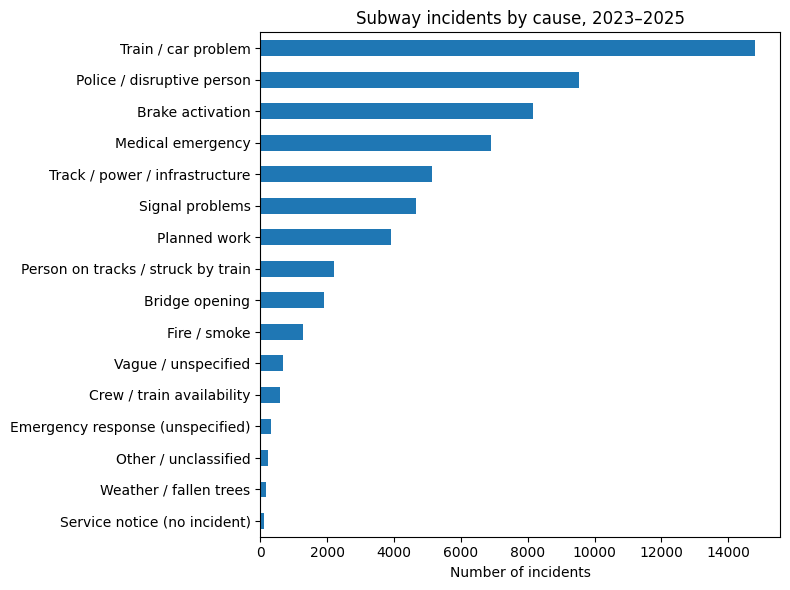

In [65]:
import matplotlib.pyplot as plt

counts_keywords.sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Subway incidents by cause, 2023–2025")
plt.xlabel("Number of incidents")
plt.ylabel("")
plt.tight_layout()
plt.show()

## **Prompt used for AI classification**

Give the AI this prompt together with the original file `MTA_Service_Alerts__Beginning_April_2020_20261020.csv`.


The AI I used was Claude Opus 5.5.

```
You are classifying New York City subway service alerts by their cause.

The attached CSV is the MTA Service Alerts dataset. Its columns are: Alert ID, Event ID, Update Number, Date, Agency, Status Label, Affected, Header, Description.

STEP 1: KEEP ONLY THE DATA BEING STUDIED
- Keep only rows where Agency is "NYCT Subway".
- Keep only rows whose Date is from January 1, 2023 through December 31, 2025.

STEP 2: TREAT EACH EVENT AS ONE INCIDENT
- Rows with the same Event ID are updates about the same incident.
- Read the Header and Description of EVERY update in the event before deciding.
- Ignore any text starting with "Planned Work Reminder" and everything after it. It describes something unrelated.

STEP 3: CHOOSE EXACTLY ONE CATEGORY PER EVENT
Use the exact category names below.

- Person on tracks / struck by train: a person on the tracks, an unauthorized person or trespasser on the tracks, someone who fell onto the tracks, or someone struck by a train.
- Police / disruptive person: someone being disruptive, an assault, a fight, an altercation, people riding outside or between train cars, someone holding the train doors, or an NYPD/police investigation or activity.
- Medical emergency: a sick or injured person, someone "in need" or "in need of assistance," a lost child, or a request for EMS/medical help.
- Fire / smoke: a fire, track fire, smoke, or smoldering condition.
- Weather / fallen trees: rain, flooding, snow, ice, storms, high winds, extreme heat, fallen trees or branches, or slippery rails or leaves. Flooding counts as weather unless the alert says it came from a water main, pipe or sprinkler.
- Track / power / infrastructure: an UNPLANNED problem with track, rails, switches, power or third-rail power, water (including water main breaks), debris or objects on the tracks, animals on the tracks, station lighting, elevators, platform equipment, or structures. Includes URGENT or EMERGENCY track maintenance, repairs and rail replacements.
- Planned work: scheduled or routine work, such as planned work, routine track or switch maintenance, signal maintenance or modernization, track inspections, upgrades, work trains, work equipment, or garbage/refuse trains.
- Signal problems: a signal problem or malfunction, or a network/communications problem affecting train control.
- Brake activation: a train's brakes activated or the emergency brake cord was pulled, with no other cause stated.
- Train / car problem: a mechanical problem, door problem, vandalized train, broken window, train car that needs cleaning or repair, stalled or disabled train, or derailment.
- Crew / train availability: fewer trains because not enough crews, operators or train cars are available.
- Bridge opening: a bridge opening for boats or marine traffic.
- Emergency response (unspecified): FDNY, NYPD or emergency teams are responding, but no update says what happened.
- Vague / unspecified: the event describes a delay or service change but no update gives a cause, or only a vague one ("an earlier incident," "an investigation," "we moved a train," "we removed a train from service").
- Service notice (no incident): not a disruption, such as shuttle bus detours for street events or roadwork, arrival-information outages, notices about LIRR, Metro-North or AirTrain, extra service, or trains resuming boarding at their regular platform.
- Test / internal message: a test message or internal note, not a real rider alert.

DECISION RULES
1. Classify by WHAT HAPPENED, not by who responded. "NYPD and EMS respond to someone in need" is Medical emergency.
2. The MTA's response is not a cause. "Remove a train from service," "move a train," "reroute trains," "run express" or "hold trains" are responses. Use them only when no update names a cause (then Vague / unspecified).
3. A person's behavior or condition outranks the equipment it affected. "Remove a train car in need of cleaning and request NYPD for a person being disruptive" is Police / disruptive person.
4. Weather outranks the equipment it affected. "Flooding that is causing a signal problem" is Weather / fallen trees.
5. Urgent or emergency work is never Planned work, even if it says "maintenance."
6. Moving an out-of-service train to storage is Planned work only if no update mentions a problem with that train.
7. An NYPD investigation or police activity with no other detail is Police / disruptive person only if no update names a more specific cause. "NYPD conducts an investigation" followed by "FDNY extinguished a track fire" is Fire / smoke.
8. Do not guess a cause that no update states.

RESOLVING EVENTS WITH SEVERAL CAUSES
If the updates of one event point to more than one category, choose the one that comes FIRST in this priority order:
1. Person on tracks / struck by train
2. Police / disruptive person
3. Medical emergency
4. Fire / smoke
5. Weather / fallen trees
6. Track / power / infrastructure
7. Planned work
8. Signal problems
9. Brake activation
10. Train / car problem
11. Crew / train availability
12. Bridge opening
13. Police / disruptive person, when the only detail is an NYPD investigation or police activity
14. Emergency response (unspecified)
15. Vague / unspecified
16. Service notice (no incident)
Use Test / internal message only when the event is a test or internal note.

THE DECIDING UPDATE
For each event, pick the single update whose text most clearly shows the category you chose. If several updates show it equally well, pick the earliest one. Report its Alert ID and copy its Header exactly as written.

OUTPUT
Return one CSV file named AI_classification.csv with exactly these columns:
event_id,ai_category,deciding_alert_id,deciding_header
- One row per Event ID, covering every event left after Step 1.
- ai_category must be one of the exact category names above.
- Put ai_category and deciding_header in double quotes.
- Before finishing, check that the number of rows equals the number of unique Event IDs after Step 1, and that each deciding_alert_id belongs to that event.
```

## **Compare with AI classification**

In [49]:
ai = pd.read_csv("AI_classification.csv")

# Change column names ("Event ID" -> "event_id") and make IDs numbers
ai.columns = ai.columns.str.strip().str.lower().str.replace(" ", "_")
ai["event_id"] = ai["event_id"].astype(int)

print(f"AI-labeled events: {len(ai):,}")

AI-labeled events: 60,668


## **Display AI category table**

In [62]:
counts_ai = ai["ai_category"].value_counts()

summary = pd.DataFrame({
    "Incidents": counts_ai,
    "Percent": (counts_ai / counts_ai.sum() * 100).round(1)
})
summary.index.name = "Cause category"

print(f"Total incidents: {counts_ai.sum():,}")
summary

Total incidents: 60,668


,Incidents,Percent
Cause category,,
Train / car problem,14813,24.4
Police / disruptive person,9774,16.1
Brake activation,8169,13.5
Medical emergency,6871,11.3
Track / power / infrastructure,5115,8.4
Signal problems,4670,7.7
Planned work,3894,6.4
Person on tracks / struck by train,2216,3.7
Bridge opening,1922,3.2


## **Chart display of AI categories**

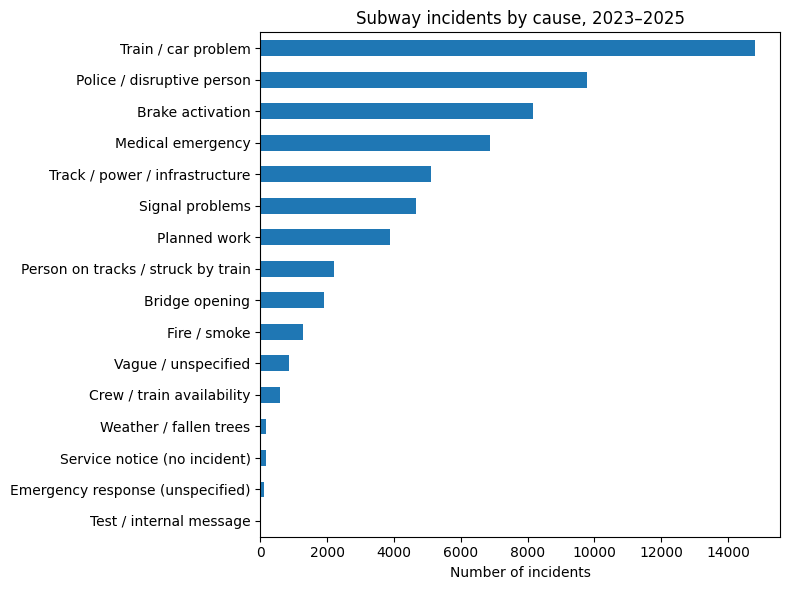

In [63]:
import matplotlib.pyplot as plt

counts_ai.sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Subway incidents by cause, 2023–2025")
plt.xlabel("Number of incidents")
plt.ylabel("")
plt.tight_layout()
plt.show()

### **Match incidents by Event ID**

In [50]:
compare = incidents.merge(ai, on="event_id", how="outer", indicator=True)

compare["_merge"].value_counts()

,count
_merge,
both,60648
right_only,20
left_only,0


In [52]:
# Events the AI labeled that are not in your data (should just be test messages and will be removed)
compare[compare["_merge"] == "right_only"][["event_id", "ai_category", "deciding_header"]]

,event_id,ai_category,deciding_header
4079,97040,Vague / unspecified,Grand St screen only
5855,100849,Test / internal message,This is a test of the MTA Service Alerts system.
8566,106853,Test / internal message,"This is a test of the MTA Service Alerts system. Please disregard this message.\n\nTesting the Rockaway Park Shuttle, Franklin Av Shuttle, and 42 St Shuttle trains."
9034,107941,Test / internal message,This is a test of the MTA Service Alerts platform. Testing the 42 St Shuttle route.\n\nPlease disregard this message.
9036,107943,Test / internal message,This is a test of the MTA Service Alerts platform. Testing the Franklin Av Shuttle route.\n\nPlease disregard this message.
9037,107944,Test / internal message,This is a test of the MTA Service Alerts platform. Testing the N route.\n\nPlease disregard this message.
11032,112545,Vague / unspecified,MARISSA NEW ALERT 1
12766,116962,Vague / unspecified,63 St - E F Weekday Alternatives LITE\n\nCOPY / DO NOT PUBLISH or DELETE
13101,117791,Test / internal message,"This is a test of the MTA Service Alerts system. Testing 42 St Shuttle, Franklin Av Shuttle, and Rockaway Park Shuttle."
13102,117792,Test / internal message,This is a test of the MTA Service Alerts system. Testing SIR.


### **Use the AI's deciding header as the alert summary**

The header is looked up by the AI's deciding_alert_id, so it is copied exactly from the data. If that ID is missing or belongs to another event, the header the AI wrote is used instead.

In [53]:
matched = (compare[compare["_merge"] == "both"]
           .drop(columns="_merge")
           .rename(columns={"ai_category": "category"})
           .copy())


alert_ids = pd.to_numeric(matched["deciding_alert_id"], errors="coerce")
header_by_alert = df.set_index("Alert ID")["Header"]
event_by_alert = df.set_index("Alert ID")["Event ID"]

valid = alert_ids.map(event_by_alert) == matched["event_id"]
matched["alert_summary"] = alert_ids.map(header_by_alert).where(valid, matched["deciding_header"])
matched = matched.drop(columns=["deciding_alert_id", "deciding_header"])

matched["categories_match"] = matched["category"] == matched["keyword_category"]

print(f"Deciding headers taken from the data: {valid.sum():,}")
print(f"Taken from the AI's text instead:    {(~valid).sum():,}")

Deciding headers taken from the data: 60,648
Taken from the AI's text instead:    0


### **Overall agreement between keywords and AI**

In [54]:
print(f"Events compared: {len(matched):,}")
print(f"Agree:    {matched['categories_match'].sum():,} ({matched['categories_match'].mean() * 100:.1f}%)")
print(f"Disagree: {(~matched['categories_match']).sum():,}")

Events compared: 60,648
Agree:    59,948 (98.8%)
Disagree: 700


### **Agreement by keyword category**

In [55]:
by_category = matched.groupby("keyword_category")["categories_match"].agg(
    Incidents="size",
    Agree="sum",
    Agreement_pct=lambda x: round(x.mean() * 100, 1))

by_category.sort_values("Incidents", ascending=False)

,Incidents,Agree,Agreement_pct
keyword_category,,,
Train / car problem,14806,14783,99.8
Police / disruptive person,9547,9545,100.0
Brake activation,8159,8155,100.0
Medical emergency,6890,6860,99.6
Track / power / infrastructure,5123,5037,98.3
Signal problems,4667,4666,100.0
Planned work,3905,3824,97.9
Person on tracks / struck by train,2218,2211,99.7
Bridge opening,1922,1922,100.0


### **Where the disagreements fall**

In [56]:
disagree = matched[~matched["categories_match"]]

pd.crosstab(disagree["keyword_category"], disagree["category"],
            rownames=["Keyword rules"], colnames=["AI"])

AI,Brake activation,Crew / train availability,Emergency response (unspecified),Medical emergency,Person on tracks / struck by train,Planned work,Police / disruptive person,Service notice (no incident),Signal problems,Track / power / infrastructure,Train / car problem,Vague / unspecified,Weather / fallen trees
Keyword rules,,,,,,,,,,,,,
Brake activation,0,0,0,0,0,2,0,0,0,1,0,0,1
Crew / train availability,0,0,0,0,0,0,0,0,0,0,0,4,0
Emergency response (unspecified),1,0,0,0,1,0,205,1,0,3,0,0,0
Medical emergency,0,0,1,0,4,0,15,0,0,2,1,7,0
Other / unclassified,0,0,0,0,0,8,3,53,1,24,2,130,0
Person on tracks / struck by train,1,0,0,2,0,0,3,0,0,0,1,0,0
Planned work,8,1,0,0,0,0,0,3,3,34,7,25,0
Police / disruptive person,0,0,0,0,0,0,0,0,0,0,0,2,0
Service notice (no incident),0,0,0,0,0,0,2,0,0,6,1,1,0


### **Examples of 5 disagreements**

In [57]:
pd.set_option("display.max_colwidth", None)
disagree[["event_id", "alert_summary", "category", "keyword_category"]].head(5)

,event_id,alert_summary,category,keyword_category
60,89301,Southbound A trains are delayed while NYPD responds to a customer altercation at High St.,Police / disruptive person,Emergency response (unspecified)
63,89304,Northbound 2 3 trains are delayed while NYPD responds to a customer altercation at 96 St.,Police / disruptive person,Emergency response (unspecified)
122,89406,Northbound 2 5 trains are running with delays after our crew assisted a person at Simpson St.,Vague / unspecified,Medical emergency
275,89711,Southbound 6 trains are running on the express track from 125 St to Grand Central-42 St while we request NYPD assistance at 86 St.,Police / disruptive person,Emergency response (unspecified)
285,89728,Northbound F trains are running with delays after we requested NYPD assistance at 21 St-Queensbridge.,Police / disruptive person,Emergency response (unspecified)


### **Category totals side by side**

In [58]:
side_by_side = pd.DataFrame({
    "Keyword rules": matched["keyword_category"].value_counts(),
    "AI": matched["category"].value_counts(),
}).fillna(0).astype(int)

side_by_side["Difference"] = side_by_side["AI"] - side_by_side["Keyword rules"]
side_by_side.sort_values("Keyword rules", ascending=False)

,Keyword rules,AI,Difference
Train / car problem,14806,14813,7
Police / disruptive person,9547,9774,227
Brake activation,8159,8169,10
Medical emergency,6890,6871,-19
Track / power / infrastructure,5123,5115,-8
Signal problems,4667,4670,3
Planned work,3905,3894,-11
Person on tracks / struck by train,2218,2216,-2
Bridge opening,1922,1922,0
Fire / smoke,1289,1289,0


### **Random sample to check by hand: 50 disagreements + 50 agreements**

Fill in `my_check` with the category you think is correct, then compare it with both methods.

In [ ]:
disagreed = matched[~matched["categories_match"]]
agreed = matched[matched["categories_match"]]

review = pd.concat([
    disagreed.sample(min(50, len(disagreed)), random_state=42),
    agreed.sample(min(50, len(agreed)), random_state=42),
])[["event_id", "categories_match", "category", "keyword_category", "alert_summary"]]

review["my_check"] = ""
review.to_csv("review_sample_100.csv", index=False)

print(f"Saved {len(review)} events to review_sample_100.csv "
      f"({(~review['categories_match']).sum()} disagreements, {review['categories_match'].sum()} agreements)")
review

Saved 100 events to review_sample_100.csv (50 disagreements, 50 agreements)


,event_id,categories_match,category,keyword_category,alert_summary,my_check
13383,118466,False,Police / disruptive person,Medical emergency,The 6:41pm SIR trip from Tottenville to St George ran express from New Dorp to St George after NYPD assisted someone off of the roadbed at New Dorp.,
43343,190302,False,Vague / unspecified,Medical emergency,Jamaica-bound E/F trains are running local from Queens Plaza/21 St-Queensbridge to Forest Hills-71 Av.,
36213,173909,False,Service notice (no incident),Vague / unspecified,Flushing-Main St-bound 7 shuttle buses are detoured because of traffic congestion on Main St/Roosevelt Ave.,
13364,118404,False,Planned work,Track / power / infrastructure,Southbound 6 trains are bypassing 14 St-Union Sq while we conduct maintenance on platform gap fillers at that station.,
29808,155934,False,Police / disruptive person,Medical emergency,Northbound B D trains are delayed while NYPD assists someone at 34 St-Herald Sq.,
...,...,...,...,...,...,...
22791,139746,True,Weather / fallen trees,Weather / fallen trees,L trains are running with delays in both directions due to today's winter storm.,
40325,184881,True,Bridge opening,Bridge opening,A/Rockaway Park Shuttle trains are delayed in both directions while the South Channel Bridge opens for marine traffic to pass.,
15633,124100,True,Planned work,Planned work,Northbound B D N Q R trains are running with delays after we moved equipment for tonight's planned work near DeKalb Av.,
12697,116758,True,Brake activation,Brake activation,Southbound B D trains are delayed while we investigate why a train's brakes activated at Grand St.,


## **Export the cleaned data**

One row per event, using the AI category as the final category.

In [ ]:
#The final data I will take as the clean dataset
export = matched[["event_id", "category", "alert_summary", "start_ts", "end_ts",
                  "duration_min", "route", "n_updates"]].copy()

export["start_ts"] = export["start_ts"].dt.strftime("%Y-%m-%d %H:%M")
export["end_ts"] = export["end_ts"].dt.strftime("%Y-%m-%d %H:%M")
export["route"] = export["route"].str.replace(", ", ",")   # "A,C,E"
export["duration_min"] = export["duration_min"].astype(int)
export["n_updates"] = export["n_updates"].astype(int)

#Sorted by event_id(since it is now the primary key)
export = export.sort_values("event_id")
export.to_csv("mta_subway_alerts_2023_2025_clean.csv", index=False)

#Edge Case in case AI missed out on labeling an event
missing_ai = (compare["_merge"] == "left_only").sum()
print(f"Exported {len(export):,} events to mta_subway_alerts_2023_2025_clean.csv")
if missing_ai:
    print(f"Note: {missing_ai:,} events had no AI category and were left out")
export.head()

Exported 60,648 events to mta_subway_alerts_2023_2025_clean.csv


,event_id,category,keyword_category,categories_match,alert_summary,start_ts,end_ts,duration_min,route,n_updates
0,89187,Fire / smoke,Fire / smoke,True,Northbound 4 5 trains are running with delays after FDNY extinguished a track fire near 138 St-Grand Concourse.,2023-01-01 00:04,2023-01-01 00:04,0,"4,5",1
1,89192,Person on tracks / struck by train,Person on tracks / struck by train,True,Southbound F trains are running with delays while we investigate a report of unauthorized people on the tracks near Delancey St-Essex St.,2023-01-01 00:27,2023-01-01 00:39,12,F,2
2,89195,Fire / smoke,Fire / smoke,True,Northbound F trains are running on the C line from Jay St-MetroTech to W 4 St-Wash Sq while FDNY responds to a track fire near Delancey St-Essex St.,2023-01-01 00:56,2023-01-01 01:52,56,F,2
3,89199,Track / power / infrastructure,Track / power / infrastructure,True,Southbound 6 trains are running express from Hunts Point Av to 3 Av-138 St while we remove debris from the tracks at Cypress Av.,2023-01-01 01:31,2023-01-01 02:48,77,"6,5",4
4,89204,Signal problems,Signal problems,True,There is no A train service between Rockaway Blvd and Ozone Park-Lefferts Blvd in both directions while we address a signal problem near Lefferts Blvd.,2023-01-01 02:05,2023-01-01 03:10,65,A,3
